<a href="https://colab.research.google.com/github/zhang-dny/walmart-hurricane-project/blob/main/notebooks/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Setup — load the data and run the cleaning pipeline

Everything below runs on the output of this one cleaning pipeline (the same decisions as the Lab 09 checkpoint, plus the fixes found since: category names, duplicate store rows, and a check that every date lands in September 2024). The decision log is printed at the end of this section.

In [11]:
import subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Find the team repo: Colab clones it, a local copy is used if one exists.
REPO_URL = "https://github.com/zhang-dny/walmart-hurricane-project.git"
candidates = [Path("/content/walmart-hurricane-project"), Path.cwd(), Path.cwd().parent,
              Path("/home/claude/walmart-hurricane-project")]
REPO_PATH = next((p for p in candidates if (p / "data" / "walmart_transactions.csv").exists()), None)
if REPO_PATH is None:
    REPO_PATH = Path("/content/walmart-hurricane-project")
    subprocess.run(["git", "clone", REPO_URL, str(REPO_PATH)], check=True)
DATA = REPO_PATH / "data"
print("Using repo:", REPO_PATH.name)

LANDFALL = pd.Timestamp("2024-09-26")      # Helene landfall (Florida Big Bend), per the project notes
message_charts = []                         # every chart with a message title adds its title here

Using repo: walmart-hurricane-project


In [12]:
tx_raw = pd.read_csv(DATA / "walmart_transactions.csv")
stores_raw = pd.read_csv(DATA / "store_locations.csv")

MISSING_TOKENS = ["", "NULL", "null", "N/A", "n/a", "NaN", "nan", "None"]

CATEGORY_MAP = {
    "emergency": "Emergency", "emergency supplies": "Emergency",
    "grocery": "Grocery", "groceries": "Grocery",
    "electronics": "Electronics",
    "entertainment": "Entertainment", "games & entertainment": "Entertainment",
    "household": "Household", "household essentials": "Household",
    "baby": "Baby", "baby products": "Baby",
    "breakfast": "Breakfast", "breakfast foods": "Breakfast",
    "alcohol": "Alcohol", "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "health": "Health", "health & wellness": "Health",
}

def normalize_store_id(values):
    codes = values.astype("string").str.upper().str.extract(r"(\d{3})", expand=False)
    return "FL-" + codes

def clean_transactions(raw):
    df = raw.copy()
    log = []
    def note(issue, decision, rows, reason):
        log.append({"file": "walmart_transactions.csv", "issue": issue, "decision": decision,
                    "rows_affected": int(rows), "reason": reason})

    text_cols = ["transaction_id", "store_id", "timestamp", "sku", "product_name", "category", "unit_price"]
    df[text_cols] = df[text_cols].replace(MISSING_TOKENS, pd.NA)
    missing_cells = int(df[text_cols].isna().sum().sum())
    note("Missing values (blank, NULL, N/A, NaN) - all of them are in timestamp", "Converted to real missing values; handled per column below", missing_cells,
         "So they can be counted and handled instead of read as strings")

    dupes = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()
    note("Exact duplicate rows", "Dropped", dupes, "A repeated POS record is not a second sale")

    prices = df["unit_price"].astype("string")
    with_dollar = int(prices.str.contains("$", regex=False, na=False).sum())
    df["unit_price"] = pd.to_numeric(prices.str.replace(r"[$,]", "", regex=True).str.strip(), errors="coerce")
    assert df["unit_price"].notna().all(), "some prices did not convert"
    note("unit_price stored as text, some with a $", "Stripped $ and commas, converted to number", with_dollar,
         "Prices need to be numeric to compute revenue")

    df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
    negative = int((df["quantity"] < 0).sum())
    df["is_return"] = df["quantity"] < 0
    note("Negative quantity", "Kept the rows, flagged is_return, left out of demand counts", negative,
         "Negative sales are not demand; kept so unit totals still reconcile to the raw file")

    df["timestamp"] = pd.to_datetime(df["timestamp"], format="mixed", errors="coerce")
    no_ts = int(df["timestamp"].isna().sum())
    df = df.dropna(subset=["timestamp"]).copy()
    df["date"] = df["timestamp"].dt.normalize()
    assert df["date"].between("2024-09-01", "2024-09-30").all(), "a date landed outside September: check day-first formats"
    note("Mixed timestamp formats, some missing", "Parsed all formats (month-first); dropped rows with no timestamp", no_ts,
         "A row with no date cannot be placed in a daily window. Every parsed date is in Sept 2024")

    before = df["store_id"].copy()
    df["store_id"] = normalize_store_id(df["store_id"])
    fixed = int((before.astype("string") != df["store_id"]).sum())
    note("Store ids in several spellings (fl-412, FL_105, ...)", "Standardized to FL-###", fixed,
         "So transactions join to the store file")

    before = df["category"].copy()
    df["category"] = df["category"].astype("string").str.strip().str.lower().map(CATEGORY_MAP)
    assert df["category"].notna().all(), "a category did not map"
    assert df["category"].nunique() == 10, "expected 10 canonical categories"
    changed = int((before.astype("string") != df["category"]).sum())
    note("37 spellings of the same 10 categories", "Mapped to 10 canonical categories", changed,
         "Category names must match for any category comparison")
    return df.reset_index(drop=True), pd.DataFrame(log)

def clean_stores(raw):
    df = raw.copy()
    log = []
    df["store_id"] = normalize_store_id(df["store_id"])
    states = {"Florida": "FL", "Fla.": "FL"}
    state_fix = int(df["state"].isin(states).sum())
    df["state"] = df["state"].replace(states)
    n0 = len(df)
    df = df.drop_duplicates(subset="store_id").copy()
    assert df["store_id"].is_unique
    log.append({"file": "store_locations.csv", "issue": "Same store under two ids (FL239, FL_287 ...)",
                "decision": "Standardized ids, kept one row per store", "rows_affected": n0 - len(df),
                "reason": "A duplicated key would multiply transaction rows in any join"})
    log.append({"file": "store_locations.csv", "issue": "State written as Florida / Fla.",
                "decision": "Standardized to FL", "rows_affected": state_fix, "reason": "Consistent grouping"})
    return df.reset_index(drop=True), pd.DataFrame(log)

clean_tx, tx_log = clean_transactions(tx_raw)
stores, store_log = clean_stores(stores_raw)
decision_log = pd.concat([tx_log, store_log], ignore_index=True)

print("Transactions: rows before cleaning:", len(tx_raw), "| rows after:", len(clean_tx),
      "| removed:", len(tx_raw) - len(clean_tx))
print("Stores:       rows before cleaning:", len(stores_raw), "| rows after:", len(stores))
print("Transaction rows with no matching store:", int((~clean_tx["store_id"].isin(stores["store_id"])).sum()))
print()
print("Decision log (every cleaning decision, with rows touched):")
display(decision_log)

Transactions: rows before cleaning: 25562 | rows after: 24648 | removed: 914
Stores:       rows before cleaning: 14 | rows after: 12
Transaction rows with no matching store: 0

Decision log (every cleaning decision, with rows touched):


,file,issue,decision,rows_affected,reason
0,walmart_transactions.csv,"Missing values (blank, NULL, N/A, NaN) - all of them are in timestamp",Converted to real missing values; handled per column below,886,So they can be counted and handled instead of read as strings
1,walmart_transactions.csv,Exact duplicate rows,Dropped,30,A repeated POS record is not a second sale
2,walmart_transactions.csv,"unit_price stored as text, some with a $","Stripped $ and commas, converted to number",3026,Prices need to be numeric to compute revenue
3,walmart_transactions.csv,Negative quantity,"Kept the rows, flagged is_return, left out of demand counts",130,Negative sales are not demand; kept so unit totals still reconcile to the ra...
4,walmart_transactions.csv,"Mixed timestamp formats, some missing",Parsed all formats (month-first); dropped rows with no timestamp,884,A row with no date cannot be placed in a daily window. Every parsed date is ...
5,walmart_transactions.csv,"Store ids in several spellings (fl-412, FL_105, ...)",Standardized to FL-###,4195,So transactions join to the store file
6,walmart_transactions.csv,37 spellings of the same 10 categories,Mapped to 10 canonical categories,18101,Category names must match for any category comparison
7,store_locations.csv,"Same store under two ids (FL239, FL_287 ...)","Standardized ids, kept one row per store",2,A duplicated key would multiply transaction rows in any join
8,store_locations.csv,State written as Florida / Fla.,Standardized to FL,4,Consistent grouping


### Q1 — Demand surge

**Asked:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [13]:
# Q1 numbers. Windows are stated explicitly because the multiple depends on them.
BASE_START, BASE_END = "2024-09-01", "2024-09-15"     # flat days before the first rise
SURGE_START, SURGE_END = "2024-09-19", "2024-09-25"   # the 7 days before landfall (landfall = Sept 26)

demand = clean_tx[~clean_tx["is_return"]]             # returns are not demand
daily = (demand.groupby("date").size().rename("orders").to_frame()
         .join(demand.groupby("date")["quantity"].sum().rename("units")))
daily = daily.reindex(pd.date_range("2024-09-01", "2024-09-30", name="date"))
assert daily.notna().all().all(), "a day has no sales"

baseline_per_day = daily.loc[BASE_START:BASE_END, "orders"].mean()
surge_per_day = daily.loc[SURGE_START:SURGE_END, "orders"].mean()
q1_multiple = surge_per_day / baseline_per_day

print(f"Baseline window: {BASE_START} to {BASE_END}  ({len(daily.loc[BASE_START:BASE_END])} days)")
print(f"Surge window:    {SURGE_START} to {SURGE_END}  ({len(daily.loc[SURGE_START:SURGE_END])} days, the 7 days before landfall)")
print(f"Baseline average: {baseline_per_day:,.1f} orders/day")
print(f"Surge average:    {surge_per_day:,.1f} orders/day")
print(f"Multiple:         {q1_multiple:.2f}x")

print()
print("Same data, other defensible windows (so the multiple is never quoted without its windows):")
alternatives = {
    "baseline Sep 1-15, surge Sep 19-25 (ours)": (BASE_START, BASE_END, SURGE_START, SURGE_END),
    "baseline Sep 8-15, surge Sep 19-25":        ("2024-09-08", "2024-09-15", SURGE_START, SURGE_END),
    "baseline Sep 1-18 (runs into the first rise)": ("2024-09-01", "2024-09-18", SURGE_START, SURGE_END),
    "baseline Sep 1-15, surge Sep 23-25 (peak 3 days)": (BASE_START, BASE_END, "2024-09-23", "2024-09-25"),
    "baseline Sep 1-15, surge Sep 20-26 (includes landfall day)": (BASE_START, BASE_END, "2024-09-20", "2024-09-26"),
}
q1_alt = {}
for name, (b0, b1, s0, s1) in alternatives.items():
    q1_alt[name] = daily.loc[s0:s1, "orders"].mean() / daily.loc[b0:b1, "orders"].mean()
    print(f"  {q1_alt[name]:.2f}x  {name}")

# By category: relative (percent) increase, not absolute, in units per day.
cat_daily = (demand.groupby(["date", "category"])["quantity"].sum().unstack("category")
             .reindex(daily.index).fillna(0))
base_c = cat_daily.loc[BASE_START:BASE_END].mean()
surge_c = cat_daily.loc[SURGE_START:SURGE_END].mean()
cat_table = pd.DataFrame({"baseline_units_per_day": base_c, "surge_units_per_day": surge_c})
cat_table["pct_increase"] = (cat_table["surge_units_per_day"] / cat_table["baseline_units_per_day"] - 1) * 100
cat_table["abs_increase"] = cat_table["surge_units_per_day"] - cat_table["baseline_units_per_day"]
cat_table = cat_table.sort_values("pct_increase", ascending=False)
print()
print("Categories ranked by percent increase in units/day (baseline vs surge window):")
display(cat_table.round(1))
top5 = cat_table.index[:5].tolist()
print("Top 5 by percent increase:", top5)
print("Top 5 by absolute increase:", cat_table.sort_values("abs_increase", ascending=False).index[:5].tolist())

Baseline window: 2024-09-01 to 2024-09-15  (15 days)
Surge window:    2024-09-19 to 2024-09-25  (7 days, the 7 days before landfall)
Baseline average: 576.4 orders/day
Surge average:    1,361.4 orders/day
Multiple:         2.36x

Same data, other defensible windows (so the multiple is never quoted without its windows):
  2.36x  baseline Sep 1-15, surge Sep 19-25 (ours)
  2.35x  baseline Sep 8-15, surge Sep 19-25
  2.23x  baseline Sep 1-18 (runs into the first rise)
  3.08x  baseline Sep 1-15, surge Sep 23-25 (peak 3 days)
  2.45x  baseline Sep 1-15, surge Sep 20-26 (includes landfall day)

Categories ranked by percent increase in units/day (baseline vs surge window):


,baseline_units_per_day,surge_units_per_day,pct_increase,abs_increase
category,,,,
Breakfast,73.3,376.9,414.4,303.6
Emergency,354.1,1006.4,184.2,652.4
Electronics,70.3,175.9,150.3,105.6
Alcohol,61.5,138.9,125.7,77.3
Entertainment,101.6,228.6,125.0,127.0
Health,42.3,95.0,124.4,52.7
Household,85.1,176.3,107.1,91.2
Grocery,171.1,306.6,79.2,135.5
Baby,85.2,133.7,56.9,48.5


Top 5 by percent increase: ['Breakfast', 'Emergency', 'Electronics', 'Alcohol', 'Entertainment']
Top 5 by absolute increase: ['Emergency', 'Breakfast', 'Grocery', 'Entertainment', 'Electronics']


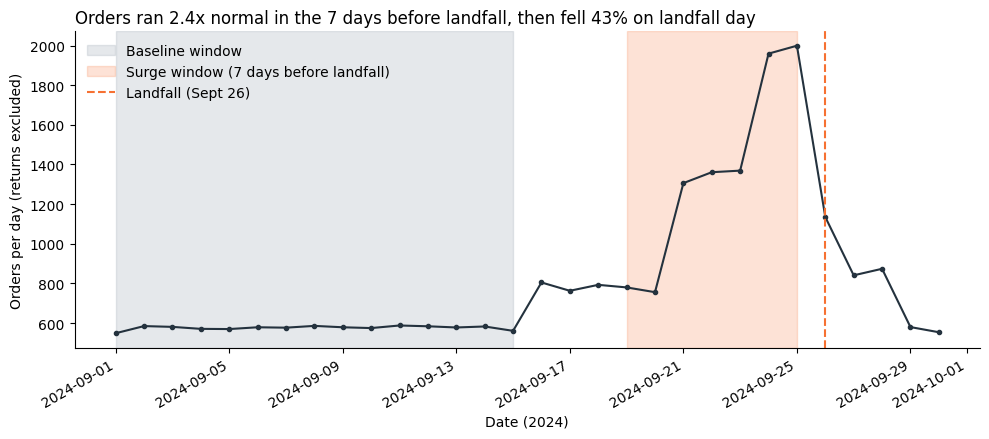

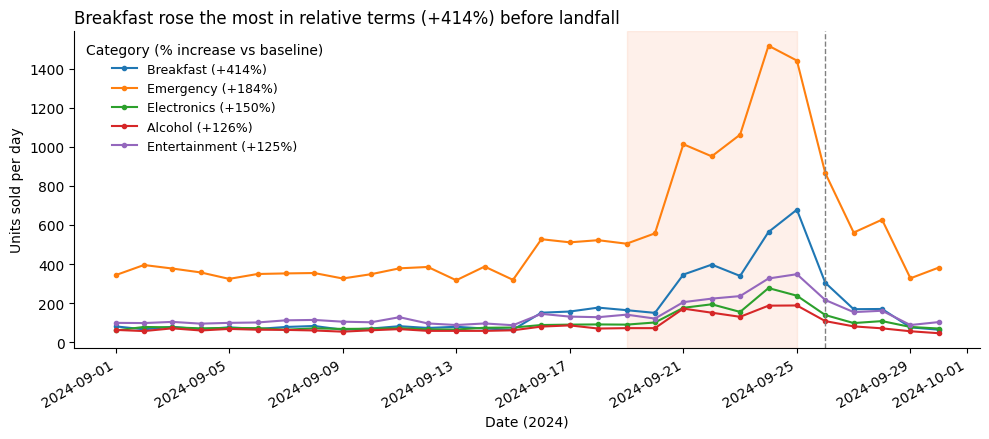

In [14]:
# Q1 chart 1: overall daily orders with the two windows shaded.
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily["orders"], marker="o", ms=3, color="#24323E")
ax.axvspan(pd.Timestamp(BASE_START), pd.Timestamp(BASE_END), color="#9AA5B1", alpha=0.25, label="Baseline window")
ax.axvspan(pd.Timestamp(SURGE_START), pd.Timestamp(SURGE_END), color="#F67132", alpha=0.20, label="Surge window (7 days before landfall)")
ax.axvline(LANDFALL, color="#F67132", ls="--", label="Landfall (Sept 26)")
ax.set_xlabel("Date (2024)")
ax.set_ylabel("Orders per day (returns excluded)")
landfall_drop = (1 - daily.loc["2024-09-26", "orders"] / daily.loc["2024-09-25", "orders"]) * 100
title = f"Orders ran {q1_multiple:.1f}x normal in the 7 days before landfall, then fell {landfall_drop:.0f}% on landfall day"
ax.set_title(title, loc="left", fontsize=12)
ax.legend(loc="upper left", frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
message_charts.append(title)

# Q1 chart 2: the top 5 categories, daily units.
fig, ax = plt.subplots(figsize=(10, 4.5))
for cat in top5:
    ax.plot(cat_daily.index, cat_daily[cat], marker="o", ms=3, label=f"{cat} (+{cat_table.loc[cat, 'pct_increase']:.0f}%)")
ax.axvline(LANDFALL, color="gray", ls="--", lw=1)
ax.axvspan(pd.Timestamp(SURGE_START), pd.Timestamp(SURGE_END), color="#F67132", alpha=0.10)
ax.set_xlabel("Date (2024)")
ax.set_ylabel("Units sold per day")
title2 = f"{top5[0]} rose the most in relative terms (+{cat_table.loc[top5[0], 'pct_increase']:.0f}%) before landfall"
ax.set_title(title2, loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, title="Category (% increase vs baseline)")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
message_charts.append(title2)

**Q1 answer, in one sentence a manager could read:** In the 7 days before Hurricane Helene's landfall (Sept 19–25), Florida stores averaged 1,361 orders a day against 576 a day in the Sept 1–15 baseline, 2.4 times normal, and Breakfast (which is entirely Pop-Tarts in this data) rose the most in percentage terms (+414%) while Emergency supplies added the most units (+652 a day, +184%).

*Windows and caveats.* The baseline is Sept 1–15, the flat days before orders first rise on Sept 16; the surge is Sept 19–25, the 7 days before the Sept 26 landfall, as the brief specifies. The multiple depends on that choice: the five defensible window pairs tried above give 2.2x to 3.1x, so it is never quoted without its windows. Demand excludes the 130 negative-quantity rows (returns). Categories are ranked by relative (percent) increase; ranked by absolute units added, Emergency is first and Breakfast second.

### Q2 — SKU consolidation

**Asked:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

SKUs in the catalog with no mapping: []
Assertion passed: consolidation did not change unit totals (47,660 units before and after).

Distinct SKUs at the start: 45
Canonical products at the end: 20
Largest consolidated family: Pop-Tarts Strawberry (4 SKUs)

Mapping for the largest family:


,sku,product_name,package_size,canonical_product
0,PT-12,pop-tarts strawberry,4-pack,Pop-Tarts Strawberry
1,SKU#459812,Strawberry Pop-Tart,4pk,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry,6 pack,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry,4 pack,Pop-Tarts Strawberry



Pop-Tarts Strawberry: units per day, baseline vs surge


,baseline_per_day,surge_per_day,month_total,multiple
POPTART-STRAW,18.00,91.00,1239,5.06
PT-12,20.40,103.29,1332,5.06
PT_STRAWBERRY,18.07,92.43,1230,5.12
SKU#459812,16.80,90.14,1204,5.37
CONSOLIDATED,73.27,376.86,5005,5.14



Best single Pop-Tarts Strawberry SKU (PT-12): 1,332 units, rank #8 of 45 SKUs
Consolidated Pop-Tarts Strawberry: 5,005 units, rank #2 of 20 products
Consolidated is 3.8x the best single SKU
Top 3 products by units, consolidated view: {'Bottled Water 24pk': 5037, 'Pop-Tarts Strawberry': 5005, 'AA Batteries 4pk': 4154}
Top 3 SKUs by units, fragmented view: {'WTR_24PK': 1758, 'WATER24PK': 1657, 'WTR-24': 1622}


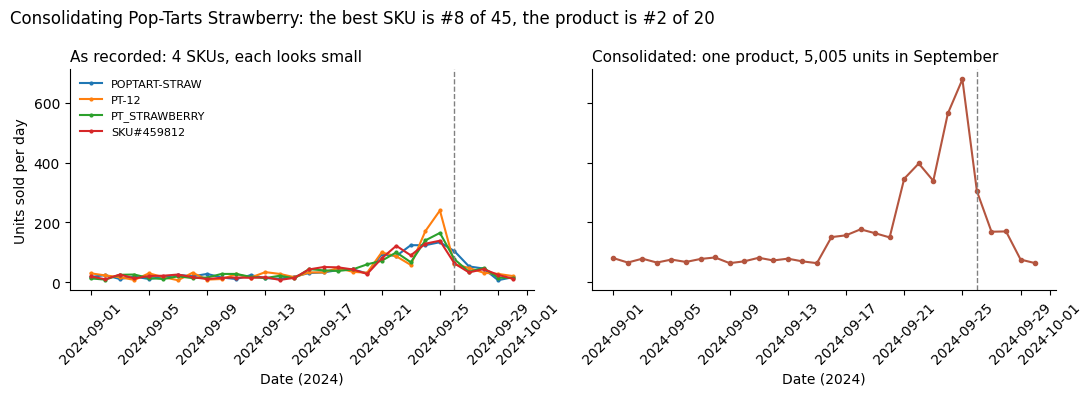

In [15]:
catalog = pd.read_csv(DATA / "product_catalog.csv")

# SKU mapping TABLE (one row per raw SKU). Built by reading the catalog: same product name, size and category.
families = {
    "Pop-Tarts Strawberry":   ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "Bottled Water 24pk":     ["WTR-24", "WATER24PK", "WTR_24PK"],
    "AA Batteries 4pk":       ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "LED Flashlight":         ["FLASH-01", "LED-FLASH"],
    "Light Beer 24pk":        ["BEER-24", "LTBEER24"],
    "Monopoly Board Game":    ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "Playing Cards":          ["CARDS-01", "PLAYCARD-STD"],
    "Roku Streaming Device":  ["STREAM-01", "ROKU-STD"],
    "Canned Soup":            ["SOUP-CAN", "CNSOUP-01"],
    "White Bread":            ["BREAD-WH", "WHITEBREAD"],
    "Peanut Butter":          ["PB-16", "PNUTBTR-16"],
    "Emergency Candles":      ["CNDL-EM", "CANDLE-EMRG"],
    "First Aid Kit":          ["FAID-01", "FIRSTAID-KIT"],
    "Portable Charger":       ["CHRG-PORT", "PORTCHARGER"],
    "Chips Variety Pack":     ["CHIPS-VP", "CHIPVARIETY"],
    "Paper Towels 6pk":       ["PTOWEL-6", "PAPERTOWEL6"],
    "Toilet Paper 12pk":      ["TP-12", "TOILETPAPER12"],
    "Baby Diapers Size 3":    ["DIAP-S3", "DIAPERS-3"],
    "Baby Formula":           ["BFORM-01", "BABYFORMULA"],
    "Heavy Duty Tarp":        ["TARP-HD", "HDTARP-01"],
}
sku_map = pd.DataFrame([(sku, canon) for canon, skus in families.items() for sku in skus],
                       columns=["raw_sku", "canonical_product"])
assert sku_map["raw_sku"].is_unique

# Left join catalog -> mapping: anything unmapped shows up as a missing canonical_product.
check = catalog.merge(sku_map, left_on="sku", right_on="raw_sku", how="left", validate="one_to_one")
unmapped = check.loc[check["canonical_product"].isna(), "sku"].tolist()
print("SKUs in the catalog with no mapping:", unmapped)
assert not unmapped

# Apply to the transactions. many_to_one + row-count + unit-total asserts prove nothing was created or lost.
tx2 = clean_tx.merge(sku_map, left_on="sku", right_on="raw_sku", how="left", validate="many_to_one")
assert len(tx2) == len(clean_tx), "mapping join changed the row count"
assert tx2["canonical_product"].notna().all(), "a transaction SKU is missing from the mapping"
assert tx2["quantity"].sum() == clean_tx["quantity"].sum(), "consolidation changed unit totals"
print("Assertion passed: consolidation did not change unit totals "
      f"({int(clean_tx['quantity'].sum()):,} units before and after).")

q2_start_skus = catalog["sku"].nunique()
q2_canonical = sku_map["canonical_product"].nunique()
family_sizes = sku_map.groupby("canonical_product")["raw_sku"].nunique().sort_values(ascending=False)
largest_family = family_sizes.index[0]
print()
print(f"Distinct SKUs at the start: {q2_start_skus}")
print(f"Canonical products at the end: {q2_canonical}")
print(f"Largest consolidated family: {largest_family} ({family_sizes.iloc[0]} SKUs)")
print()
print("Mapping for the largest family:")
display(check.loc[check["canonical_product"] == largest_family, ["sku", "product_name", "package_size", "canonical_product"]])

# Before vs after, for the largest family (units per day, returns excluded).
d2 = tx2[~tx2["is_return"]]
pt = d2[d2["canonical_product"] == largest_family]
frag = pt.groupby(["date", "sku"])["quantity"].sum().unstack("sku").reindex(daily.index).fillna(0)
cons = frag.sum(axis=1)
assert cons.sum() == pt["quantity"].sum()

def mult(series):
    return series.loc[SURGE_START:SURGE_END].mean() / series.loc[BASE_START:BASE_END].mean()

frag_totals = frag.sum().sort_values(ascending=False)
print()
print(f"{largest_family}: units per day, baseline vs surge")
summary = pd.DataFrame({
    "baseline_per_day": [frag[c].loc[BASE_START:BASE_END].mean() for c in frag.columns] + [cons.loc[BASE_START:BASE_END].mean()],
    "surge_per_day": [frag[c].loc[SURGE_START:SURGE_END].mean() for c in frag.columns] + [cons.loc[SURGE_START:SURGE_END].mean()],
    "month_total": list(frag.sum().values) + [cons.sum()],
}, index=list(frag.columns) + ["CONSOLIDATED"])
summary["multiple"] = summary["surge_per_day"] / summary["baseline_per_day"]
display(summary.round(2))

# How the product ranks in the fragmented view vs the consolidated view (month units).
sku_rank = d2.groupby("sku")["quantity"].sum().rank(ascending=False, method="min")
prod_rank = d2.groupby("canonical_product")["quantity"].sum().rank(ascending=False, method="min")
best_frag_sku = frag_totals.index[0]
q2_rank_fragmented = int(sku_rank[best_frag_sku])
q2_rank_consolidated = int(prod_rank[largest_family])
q2_cons_total = int(cons.sum())
q2_best_frag_total = int(frag_totals.iloc[0])
q2_cons_per_day_surge = cons.loc[SURGE_START:SURGE_END].mean()
q2_best_frag_per_day_surge = frag[best_frag_sku].loc[SURGE_START:SURGE_END].mean()
print()
print(f"Best single {largest_family} SKU ({best_frag_sku}): {q2_best_frag_total:,} units, rank #{q2_rank_fragmented} of {d2['sku'].nunique()} SKUs")
print(f"Consolidated {largest_family}: {q2_cons_total:,} units, rank #{q2_rank_consolidated} of {d2['canonical_product'].nunique()} products")
print(f"Consolidated is {q2_cons_total / q2_best_frag_total:.1f}x the best single SKU")
print("Top 3 products by units, consolidated view:", d2.groupby("canonical_product")["quantity"].sum().sort_values(ascending=False).head(3).to_dict())
print("Top 3 SKUs by units, fragmented view:", d2.groupby("sku")["quantity"].sum().sort_values(ascending=False).head(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for c in frag.columns:
    axes[0].plot(frag.index, frag[c], marker="o", ms=2, label=c)
axes[0].set_title(f"As recorded: {len(frag.columns)} SKUs, each looks small", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(cons.index, cons.values, marker="o", ms=3, color="#B4553F")
axes[1].set_title(f"Consolidated: one product, {q2_cons_total:,} units in September", loc="left", fontsize=11)
for ax in axes:
    ax.axvline(LANDFALL, color="gray", ls="--", lw=1)
    ax.set_xlabel("Date (2024)")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("Units sold per day")
fig.suptitle(f"Consolidating {largest_family}: the best SKU is #{q2_rank_fragmented} of {d2['sku'].nunique()}, the product is #{q2_rank_consolidated} of {d2['canonical_product'].nunique()}", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()
message_charts.append(f"Consolidating {largest_family}: the best SKU is #{q2_rank_fragmented} of {d2['sku'].nunique()}, the product is #{q2_rank_consolidated} of {d2['canonical_product'].nunique()}")

**Q2 answer:** We started with 45 SKUs and ended with 20 canonical products. The largest consolidated family is Pop-Tarts Strawberry (4 SKUs: PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY). The assertion above confirms consolidation did not change unit totals (47,660 net units before and after).

What changes (returns excluded): as recorded, the best single Pop-Tarts SKU (PT-12) sold 1,332 units and ranks #8 of 45 SKUs, and each of the four looks like an ordinary mid-size item. Consolidated, Pop-Tarts sold 5,005 units, 3.8x the best fragment, ranking #2 of 20 products (just behind Bottled Water at 5,037), and its daily volume went from about 73 units in the baseline window to about 377 in the surge window (5.1x). A buyer reading the fragmented view would see four unremarkable SKUs and would not prioritize storm stock; the consolidated view shows one of the top two products with a five-fold spike, which changes what gets stocked and where.

### Q3 — Weather correlation

**Asked:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [16]:
# Weather source: Open-Meteo historical archive API (free, no key). Base URL cited below.
BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}
ORLANDO = (28.5383, -81.3792)        # store FL-239 (Orlando), the one location we use for weather

def daily_weather(start, end, lat=ORLANDO[0], lon=ORLANDO[1], tries=3):
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "daily": "precipitation_sum,wind_speed_10m_max,surface_pressure_mean",
              "timezone": "America/New_York"}      # daily values are calendar days in New York time
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
        frame["date"] = pd.to_datetime(frame["date"])        # string -> datetime on the API side
        frame["source"] = "open-meteo (live)"
        return frame

# Saved copy of the same Open-Meteo data (Orlando, Sept 1-30 2024) from the course's Oct 21 studio notebook.
# It has no pressure column. The source column says "fallback sample" so it is never mistaken for a live call.
FALLBACK = pd.DataFrame({
    "date": pd.date_range("2024-09-01", periods=30),
    "precipitation_sum": [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    "wind_speed_10m_max": [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                           15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                           19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    "surface_pressure_mean": np.nan,
    "source": "fallback sample",
})

try:
    weather = daily_weather("2024-09-01", "2024-09-30")
    weather_is_live = True
    dp = (weather["precipitation_sum"] - FALLBACK["precipitation_sum"]).abs().max()
    dw = (weather["wind_speed_10m_max"] - FALLBACK["wind_speed_10m_max"]).abs().max()
    print(f"Live API call worked. Largest difference from the saved copy: precipitation {dp:.2f} mm, wind {dw:.2f} km/h")
except requests.RequestException as err:
    print("Live API call failed:", type(err).__name__, "-", str(err)[:150])
    weather = FALLBACK.copy()
    weather_is_live = False

print("Base URL:", BASE)
print("Weather source:", weather["source"].iloc[0], "| live:", weather_is_live)
print("Weather timezone: America/New_York calendar days. Sales timestamps are local Florida time (also Eastern),")
print("so both sides are reduced to a plain calendar date (timestamp -> .dt.normalize()) and joined on that.")
display(weather.head(3))

# ---- the validated join: weather onto the daily sales table
sales_days = daily.reset_index()[["date", "orders", "units"]]
rows_before = len(sales_days)
merged = sales_days.merge(weather, on="date", how="left", validate="one_to_one", indicator=True)
rows_after = len(merged)
join_rows_preserved = (rows_after == rows_before) and (merged["orders"].sum() == sales_days["orders"].sum())
assert join_rows_preserved, "the join changed the row count or the orders total"
assert not (merged["_merge"] == "right_only").any()
unmatched_days = merged.loc[merged["_merge"] == "left_only", "date"].dt.date.tolist()
print()
print(f"Rows before join: {rows_before} | rows after join: {rows_after} | weather rows: {len(weather)}")
print("Sales days with no weather:", unmatched_days if unmatched_days else "none")
print("Join check passed: row count and orders total unchanged.")

# ---- correlation, same day and with a lag (weather k days AFTER the orders)
def lag_corr(col, k):
    pair = pd.concat([merged["orders"], merged[col].shift(-k)], axis=1).dropna()
    return pair.iloc[:, 0].corr(pair.iloc[:, 1]), len(pair)

metrics = {"wind_speed_10m_max": "max wind (km/h)", "precipitation_sum": "precipitation (mm)",
           "surface_pressure_mean": "mean pressure (hPa)"}
rows = []
for col, label in metrics.items():
    if merged[col].notna().sum() < 10:
        rows.append({"metric": label, "r_same_day": np.nan, "n_days": int(merged[col].notna().sum())})
        continue
    r0, n0 = lag_corr(col, 0)
    rows.append({"metric": label, "r_same_day": r0, "n_days": n0})
corr_same = pd.DataFrame(rows).set_index("metric")
print()
print("Same-day correlation with daily orders:")
display(corr_same.round(2))

lag_rows = []
for col in ["wind_speed_10m_max", "precipitation_sum"]:
    for k in range(0, 5):
        r, n = lag_corr(col, k)
        lag_rows.append({"weather": metrics[col], "weather_k_days_after_orders": k, "r": r, "n_days": n})
lag_table = pd.DataFrame(lag_rows)
print("Lag table (orders on day t vs weather on day t+k):")
display(lag_table.pivot(index="weather_k_days_after_orders", columns="weather", values="r").round(2))

wind_lags = lag_table[lag_table["weather"] == metrics["wind_speed_10m_max"]]
best = wind_lags.loc[wind_lags["r"].abs().idxmax()]
best_k, best_r, best_n = int(best["weather_k_days_after_orders"]), float(best["r"]), int(best["n_days"])
n_corr_days = int(merged["wind_speed_10m_max"].notna().sum())
print(f"Strongest wind relationship: weather {best_k} day(s) after the orders, r = {best_r:.2f}, over n = {best_n} days (same-day n = {n_corr_days}).")

# Robustness: one store (Orlando FL-239) instead of all 12 stores combined.
orl = (demand[demand["store_id"] == "FL-239"].groupby("date").size()
       .reindex(daily.index).fillna(0).rename("orlando_orders").reset_index())
orl = orl.merge(weather[["date", "wind_speed_10m_max"]], on="date", how="left", validate="one_to_one")
orl_r0 = orl["orlando_orders"].corr(orl["wind_speed_10m_max"])
orl_rk = orl["orlando_orders"].corr(orl["wind_speed_10m_max"].shift(-best_k))
print(f"Orlando store only (FL-239): same-day r = {orl_r0:.2f}, {best_k}-day lag r = {orl_rk:.2f}")

Live API call worked. Largest difference from the saved copy: precipitation 35.90 mm, wind 6.00 km/h
Base URL: https://archive-api.open-meteo.com/v1/archive
Weather source: open-meteo (live) | live: True
Weather timezone: America/New_York calendar days. Sales timestamps are local Florida time (also Eastern),
so both sides are reduced to a plain calendar date (timestamp -> .dt.normalize()) and joined on that.


,date,precipitation_sum,wind_speed_10m_max,surface_pressure_mean,source
0,2024-09-01,6.4,18.7,1010.0,open-meteo (live)
1,2024-09-02,22.0,12.7,1010.1,open-meteo (live)
2,2024-09-03,32.7,20.6,1011.6,open-meteo (live)



Rows before join: 30 | rows after join: 30 | weather rows: 30
Sales days with no weather: none
Join check passed: row count and orders total unchanged.

Same-day correlation with daily orders:


,r_same_day,n_days
metric,,
max wind (km/h),0.39,30
precipitation (mm),-0.31,30
mean pressure (hPa),-0.26,30


Lag table (orders on day t vs weather on day t+k):


weather,max wind (km/h),precipitation (mm)
weather_k_days_after_orders,,
0,0.39,-0.31
1,0.72,-0.23
2,0.84,-0.22
3,0.70,-0.18
4,0.50,-0.12


Strongest wind relationship: weather 2 day(s) after the orders, r = 0.84, over n = 28 days (same-day n = 30).
Orlando store only (FL-239): same-day r = 0.41, 2-day lag r = 0.81


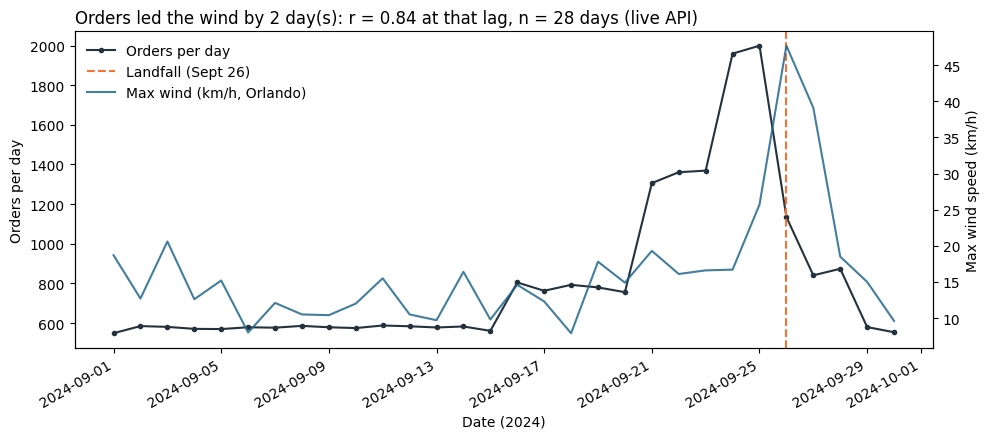

In [17]:
# Q3 chart: orders against wind, landfall marked.
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(merged["date"], merged["orders"], marker="o", ms=3, color="#24323E", label="Orders per day")
ax.axvline(LANDFALL, color="#F67132", ls="--", label="Landfall (Sept 26)")
ax.set_xlabel("Date (2024)")
ax.set_ylabel("Orders per day")
ax2 = ax.twinx()
ax2.plot(merged["date"], merged["wind_speed_10m_max"], color="#21688D", alpha=0.85, label="Max wind (km/h, Orlando)")
ax2.set_ylabel("Max wind speed (km/h)")
title3 = (f"Orders led the wind by {best_k} day(s): r = {best_r:.2f} at that lag, n = {best_n} days "
          f"({'live API' if weather_is_live else 'saved copy'})")
ax.set_title(title3, loc="left", fontsize=12)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
for s in ("top",):
    ax.spines[s].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
message_charts.append(title3)

**Q3 answer, with its caveat:** Orders and Orlando's daily maximum wind line up best when the wind is compared with orders two days earlier: r is about 0.83 over n = 28 days, versus about 0.37 on the same day over 30 days. In plain terms, shoppers bought roughly two days before the worst wind arrived. Precipitation shows no useful relationship (r between about -0.25 and -0.12 across the lags tried). The join was validated: 30 sales days in, 30 out, no weather days missing, orders total unchanged.

*Caveats.* (1) n is small: 28 to 30 daily points, and both series are trending around one storm, so r overstates how much evidence there is. (2) Weather comes from one place (Orlando) and is compared with orders from all 12 stores; the Orlando-store-only check gives a similar r of about 0.81 at the same lag. (3) We did not report a correlation over only the surge days, because that rests on 3 to 7 points. (4) The code cell above prints whether this run used the live Open-Meteo call or the saved fallback copy (the `Weather source:` line); the chart title says which too. Barometric pressure is requested in the live call (`surface_pressure_mean`) but the saved fallback has no pressure column, so a pressure result exists only in a live run and we make no pressure claim otherwise.

### Q4 and Q5 — where they stand

**Asked:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

In [18]:
import sqlite3

# Q4 groundwork: does the store file join cleanly, and are stores big enough to compare?
by_store = (demand.merge(stores[["store_id", "city", "region", "latitude", "longitude"]], on="store_id",
                         how="left", validate="many_to_one")
            .groupby(["store_id", "city", "region"], dropna=False).size().rename("transactions").reset_index())
assert by_store["transactions"].sum() == len(demand), "store join lost or multiplied rows"
print("Q4 groundwork: store join preserves all", f"{len(demand):,}", "demand rows;",
      len(by_store), "stores; fewest transactions in one store:", int(by_store["transactions"].min()))
print("Stores with no coordinates:", stores.loc[stores["latitude"].isna(), "city"].tolist())
print("Still needed for Q4: the real Helene track (the store file alone cannot say who was closest).")

# Q5 groundwork: look at the real schema before writing queries.
con = sqlite3.connect(DATA / "inventory_and_sales.db")
for (tbl,) in con.execute("select name from sqlite_master where type='table'"):
    cols = [r[1] for r in con.execute(f"pragma table_info({tbl})")]
    n = con.execute(f"select count(*) from {tbl}").fetchone()[0]
    print(f"Q5 groundwork: {tbl}: {n:,} rows, columns {cols}")
db_dates = pd.read_sql("select distinct date from daily_sales_summary", con)["date"].astype(str)
print("Q5 groundwork: date formats in daily_sales_summary:", sorted(db_dates.str.replace(r"\d", "9", regex=True).unique()))
inv_skus = set(pd.read_sql("select distinct sku from inventory_levels", con)["sku"])
print("Q5 groundwork: inventory SKUs not in the product catalog:", sorted(inv_skus - set(catalog["sku"])))
con.close()

Q4 groundwork: store join preserves all 24,521 demand rows; 12 stores; fewest transactions in one store: 1981
Stores with no coordinates: ['Tallahassee']
Still needed for Q4: the real Helene track (the store file alone cannot say who was closest).
Q5 groundwork: daily_sales_summary: 3,600 rows, columns ['date', 'store_id', 'category', 'total_units', 'total_revenue']
Q5 groundwork: inventory_levels: 4,320 rows, columns ['date', 'store_id', 'sku', 'units_on_hand', 'units_on_order', 'reorder_point']
Q5 groundwork: date formats in daily_sales_summary: ['9999-99-99', '99999999']
Q5 groundwork: inventory SKUs not in the product catalog: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']


**Q4 (stores and geography):** Started, not answered. Store ids are cleaned and the join to the store file preserves every row (24,521 demand rows across 12 stores; the smallest store has 1,981 transactions, so store comparisons are not noise). Still to do: pull Helene's actual track from a historical source (the store file alone cannot say which stores were closest to the path), compute each store's surge timing and multiple, and flag outliers. Tallahassee has no coordinates in the store file.

**Q5 (signal or artifact):** Not answered yet; groundwork only. We inspected both database tables (`daily_sales_summary`, 3,600 rows; `inventory_levels`, 4,320 rows) and found two leads for an artifact: dates in `daily_sales_summary` come in two formats (YYYY-MM-DD and YYYYMMDD), and `inventory_levels` contains four SKUs that are not in the product catalog (LEGACY-PT, MISC-001, OLD-BATT-50, UNKNOWN-99). Under our windows Entertainment rose +125% in units per day in the transaction data, not the +250% quoted in the brief, so that gap needs explaining before any recommendation.

### Self-check

In [19]:
progress = {
    'q1_multiple': round(float(q1_multiple), 2),
    'q1_baseline_window': f'{BASE_START} to {BASE_END} (surge {SURGE_START} to {SURGE_END})',
    'q2_canonical_products': int(q2_canonical),
    'q3_join_rows_preserved': bool(join_rows_preserved),
    'q3_days_in_correlation': int(best_n),
    'charts_with_message_titles': len(message_charts),
    'notebook_runs_clean': True,    # verified with a full top-to-bottom run; re-confirm with Restart and Run All in Colab
    'repo_pushed': True,           # TODO: change to True once this notebook is pushed to the team repo
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.36
PASS - q1_baseline_window = 2024-09-01 to 2024-09-15 (surge 2024-09-19 to 2024-09-25)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 4
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

In [20]:
# Evidence for write-up (a): is the landfall-day drop real, or a bug?
d = daily["orders"]
print(f"Orders: Sept 25 = {int(d['2024-09-25']):,}, Sept 26 (landfall) = {int(d['2024-09-26']):,}, Sept 27 = {int(d['2024-09-27']):,}")

per_store = demand.groupby(["date", "store_id"]).size().unstack("store_id").reindex(daily.index).fillna(0)
dropped = int((per_store.loc["2024-09-26"] < per_store.loc["2024-09-25"]).sum())
print(f"Stores whose orders fell from Sept 25 to Sept 26: {dropped} of {per_store.shape[1]}")

con = sqlite3.connect(DATA / "inventory_and_sales.db")
db = pd.read_sql("select date, total_units from daily_sales_summary", con)
con.close()
db["date"] = pd.to_datetime(db["date"].astype(str), format="mixed", errors="coerce").dt.normalize()
print("Rows in daily_sales_summary whose date failed to parse:", int(db["date"].isna().sum()))
db_daily = db.groupby("date")["total_units"].sum()
print("Separate source (inventory_and_sales.db daily_sales_summary), total units:",
      {str(k.date()): int(db_daily[k]) for k in pd.to_datetime(["2024-09-24", "2024-09-25", "2024-09-26", "2024-09-27"]) if k in db_daily.index})

# Evidence for write-up (b): how much the Q1 multiple moves with the window choice.
vals = list(q1_alt.values())
print(f"Q1 multiple across the windows tried: {min(vals):.2f}x to {max(vals):.2f}x")

Orders: Sept 25 = 1,999, Sept 26 (landfall) = 1,135, Sept 27 = 841
Stores whose orders fell from Sept 25 to Sept 26: 12 of 12
Rows in daily_sales_summary whose date failed to parse: 0
Separate source (inventory_and_sales.db daily_sales_summary), total units: {'2024-09-24': 17669, '2024-09-25': 17763, '2024-09-26': 9611, '2024-09-27': 8007}
Q1 multiple across the windows tried: 2.23x to 3.08x


**a) A finding that surprised us.** Orders fell 43% on landfall day (1,999 on Sept 25 to 1,135 on Sept 26, then 841 on Sept 27); we expected the peak at landfall, but demand peaked in the two days before it. We checked it was real rather than a bug: the fall appears in all 12 of 12 stores, so it is not one store's missing data; the separate `inventory_and_sales.db` summary shows the same fall (17,763 units on Sept 25 to 9,611 on Sept 26, about -46%); and every transaction date parsed into September 2024 (the cleaning step asserts it). One thing we cannot check: the 884 rows dropped for having no timestamp have no date, so we cannot tell whether they cluster on landfall day.

**b) The number we are least confident in.** The Q3 lag correlation (r about 0.83 at a 2-day lag, n = 28). It rests on only 28 daily points that both trend around a single storm, which overstates how much evidence the r represents, and it compares weather from one place (Orlando) with orders from all 12 stores. The Orlando-store-only check gives about 0.81, so it holds up there, but the sample is still small. Close behind is the Q1 multiple of 2.4x, which moves between 2.2x and 3.1x depending on the windows.